In [1]:

# ============================================================
# TAHAP 1: DATA UNDERSTANDING
# ANALISIS DERET WAKTU PENJUALAN SELURUH PRODUK
# ============================================================

# Pengolahan data
import pandas as pd
import numpy as np

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Peringatan
import warnings
warnings.filterwarnings("ignore")

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Seluruh library berhasil diimpor.")


Seluruh library berhasil diimpor.


In [4]:

# ============================================================
# MEMBACA DATASET
# ============================================================

file_path = "Report Penjualan Item Maret-Juni.xlsx"

df_raw = pd.read_excel(
    file_path,
    sheet_name="Query Report"
)

print("Dataset berhasil dibaca!")
print("Nama file:", file_path)
print("Ukuran dataset:", df_raw.shape)


Dataset berhasil dibaca!
Nama file: Report Penjualan Item Maret-Juni.xlsx
Ukuran dataset: (34563, 13)


In [5]:

# ============================================================
# EKSPLORASI STRUKTUR DATASET
# ============================================================

print("=" * 65)
print("INFORMASI DATASET")
print("=" * 65)

print("\nJumlah baris dan kolom:")
print(df_raw.shape)

print("\nNama variabel:")
print(df_raw.columns.tolist())

print("\nLima data pertama:")
display(df_raw.head())

print("\nLima data terakhir:")
display(df_raw.tail())

print("\nInformasi tipe data:")
df_raw.info()


INFORMASI DATASET

Jumlah baris dan kolom:
(34563, 13)

Nama variabel:
['Tanggal', 'Sales Invoice', 'Customer', 'Branch', 'Item Code', 'Item Name', 'Sub Brand', 'Qty', 'Harga', 'Total Harga', 'Retur', 'Diskon', 'Total']

Lima data pertama:


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1,750000,750000,0,0,750000
1,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6,109000,654000,0,0,654000
2,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12,116000,1392000,0,0,1392000
3,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3,159000,477000,0,0,477000
4,2026-03-01,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1,116000,116000,0,0,116000



Lima data terakhir:


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
34558,2026-06-30,ACC-SINV-RET-2026-00156,Shopee,MKP,1010201011,IL VASTO Classico Hair Cream Colorant 1.0 Blac...,Classico Vegan,1,154000,0,154000,0,-154000
34559,2026-06-30,ACC-SINV-RET-2026-00157,Shopee,MKP,1010401025,IL Vasto Volume 10 Creme Peroxide 500 ML,Peroxide,1,78100,0,78100,0,-78100
34560,2026-06-30,ACC-SINV-RET-2026-00158,Shopee,MKP,1050201011,Sleek Et Lisse Strong Curly Hair Step 1 & Step...,Straight System,1,116000,0,116000,0,-116000
34561,2026-06-30,ACC-SINV-RET-2026-00159,Shopee,MKP,1010401052,IL Vasto Volume 40 Creme Peroxide 200 ML,Peroxide,1,82000,0,82000,0,-82000
34562,NaT,NaN,NaN,NaN,NaN,NaN,NaN,95713,6576375723,15709501774,45485950,346422351,15317593473



Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


In [6]:

# ============================================================
# IDENTIFIKASI KARAKTERISTIK VARIABEL
# ============================================================

struktur_data = pd.DataFrame({
    "Variabel": df_raw.columns,
    "Tipe Data": df_raw.dtypes.astype(str).values,
    "Jumlah Data Terisi": df_raw.notna().sum().values,
    "Missing Values": df_raw.isna().sum().values,
    "Jumlah Nilai Unik": df_raw.nunique().values
})

display(struktur_data)


,Variabel,Tipe Data,Jumlah Data Terisi,Missing Values,Jumlah Nilai Unik
0,Tanggal,datetime64[ns],34562,1,119
1,Sales Invoice,object,34562,1,6254
2,Customer,object,34562,1,1307
3,Branch,object,34562,1,17
4,Item Code,object,34562,1,238
5,Item Name,object,34562,1,237
6,Sub Brand,object,34562,1,31
7,Qty,int64,34563,0,63
8,Harga,int64,34563,0,277
9,Total Harga,int64,34563,0,1100


In [7]:

# ============================================================
# DATA DICTIONARY
# ============================================================

data_dictionary = pd.DataFrame({
    "Variabel": [
        "Tanggal",
        "Sales Invoice",
        "Customer",
        "Branch",
        "Item Code",
        "Item Name",
        "Sub Brand",
        "Qty",
        "Harga",
        "Total Harga",
        "Retur",
        "Diskon",
        "Total"
    ],

    "Deskripsi": [
        "Tanggal transaksi penjualan.",
        "Nomor identifikasi transaksi penjualan.",
        "Identitas pelanggan.",
        "Identitas cabang transaksi.",
        "Kode identifikasi produk.",
        "Nama produk.",
        "Kategori atau sub-brand produk.",
        "Jumlah unit produk dalam transaksi.",
        "Harga satuan produk.",
        "Nilai harga produk.",
        "Informasi nilai atau jumlah retur.",
        "Nilai potongan harga.",
        "Nilai akhir transaksi."
    ],

    "Peran dalam Penelitian": [
        "Variabel waktu",
        "Identifikasi transaksi",
        "Informasi pendukung",
        "Informasi pendukung",
        "Identifikasi produk",
        "Informasi pendukung",
        "Informasi pendukung",
        "Kandidat variabel target",
        "Informasi pendukung",
        "Informasi pendukung",
        "Informasi pendukung",
        "Informasi pendukung",
        "Informasi pendukung"
    ]
})

display(data_dictionary)


,Variabel,Deskripsi,Peran dalam Penelitian
0,Tanggal,Tanggal transaksi penjualan.,Variabel waktu
1,Sales Invoice,Nomor identifikasi transaksi penjualan.,Identifikasi transaksi
2,Customer,Identitas pelanggan.,Informasi pendukung
3,Branch,Identitas cabang transaksi.,Informasi pendukung
4,Item Code,Kode identifikasi produk.,Identifikasi produk
5,Item Name,Nama produk.,Informasi pendukung
6,Sub Brand,Kategori atau sub-brand produk.,Informasi pendukung
7,Qty,Jumlah unit produk dalam transaksi.,Kandidat variabel target
8,Harga,Harga satuan produk.,Informasi pendukung
9,Total Harga,Nilai harga produk.,Informasi pendukung


In [8]:

# ============================================================
# PEMERIKSAAN MISSING VALUES
# ============================================================

missing_data = pd.DataFrame({
    "Jumlah Missing": df_raw.isnull().sum(),
    "Persentase Missing (%)": (
        df_raw.isnull().mean() * 100
    )
})

display(missing_data)

print(
    "Total missing values:",
    df_raw.isnull().sum().sum()
)


,Jumlah Missing,Persentase Missing (%)
Tanggal,1,0.00
Sales Invoice,1,0.00
Customer,1,0.00
Branch,1,0.00
Item Code,1,0.00
Item Name,1,0.00
Sub Brand,1,0.00
Qty,0,0.00
Harga,0,0.00
Total Harga,0,0.00


Total missing values: 7


In [9]:

# ============================================================
# IDENTIFIKASI BARIS TRANSAKSI DAN BARIS TANPA TANGGAL
# ============================================================

df_raw["Tanggal"] = pd.to_datetime(
    df_raw["Tanggal"],
    errors="coerce"
)

# Data dengan tanggal valid
df_transaksi = df_raw[
    df_raw["Tanggal"].notna()
].copy()

# Data tanpa tanggal
df_tanpa_tanggal = df_raw[
    df_raw["Tanggal"].isna()
].copy()

print("Jumlah seluruh baris:", len(df_raw))
print("Jumlah transaksi bertanggal:", len(df_transaksi))
print("Jumlah baris tanpa tanggal:", len(df_tanpa_tanggal))

print("\nBaris tanpa tanggal:")
display(df_tanpa_tanggal)


Jumlah seluruh baris: 34563
Jumlah transaksi bertanggal: 34562
Jumlah baris tanpa tanggal: 1

Baris tanpa tanggal:


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
34562,NaT,NaN,NaN,NaN,NaN,NaN,NaN,95713,6576375723,15709501774,45485950,346422351,15317593473


In [10]:

# ============================================================
# MEMISAHKAN DATA TRANSAKSI DAN BARIS REKAPITULASI
# ============================================================

# Mengambil baris yang memiliki tanggal valid
df_transaksi = df_raw[
    df_raw["Tanggal"].notna()
].copy()

# Mengambil baris yang tidak memiliki tanggal
df_rekap = df_raw[
    df_raw["Tanggal"].isna()
].copy()

print("Jumlah data awal:", len(df_raw))
print("Jumlah data transaksi:", len(df_transaksi))
print("Jumlah baris rekapitulasi:", len(df_rekap))

print("\nTotal Qty transaksi:")
print(df_transaksi["Qty"].sum())

print("\nTotal Qty pada baris rekapitulasi:")
print(df_rekap["Qty"].sum())


Jumlah data awal: 34563
Jumlah data transaksi: 34562
Jumlah baris rekapitulasi: 1

Total Qty transaksi:
95713

Total Qty pada baris rekapitulasi:
95713


In [11]:

# ============================================================
# PEMERIKSAAN DUPLIKASI
# ============================================================

jumlah_duplikat = df_transaksi.duplicated().sum()

print("Jumlah baris duplikat identik:", jumlah_duplikat)

print("\nContoh baris duplikat:")
display(
    df_transaksi[
        df_transaksi.duplicated(keep=False)
    ].head(10)
)

# Pemeriksaan kombinasi tanggal, invoice, dan item
kolom_kunci = [
    "Tanggal",
    "Sales Invoice",
    "Item Code"
]

jumlah_duplikat_kunci = (
    df_transaksi.duplicated(
        subset=kolom_kunci,
        keep=False
    ).sum()
)

print(
    "\nJumlah baris dengan kombinasi tanggal, "
    "invoice, dan item yang berulang:",
    jumlah_duplikat_kunci
)


Jumlah baris duplikat identik: 3353

Contoh baris duplikat:


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
9,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1,103000,103000,0,0,103000
10,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1,103000,103000,0,0,103000
11,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2,103000,206000,0,0,206000
12,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2,103000,206000,0,0,206000
32,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000
33,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000
35,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000
36,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7,142000,994000,0,0,994000
37,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,1,142000,142000,0,0,142000
38,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7,142000,994000,0,0,994000



Jumlah baris dengan kombinasi tanggal, invoice, dan item yang berulang: 7148


In [12]:

# ============================================================
# IDENTIFIKASI PERIODE PENGAMATAN
# ============================================================

tanggal_awal = df_transaksi["Tanggal"].min()
tanggal_akhir = df_transaksi["Tanggal"].max()

kalender_harian = pd.date_range(
    start=tanggal_awal,
    end=tanggal_akhir,
    freq="D"
)

tanggal_transaksi = pd.DatetimeIndex(
    df_transaksi["Tanggal"].dt.normalize().unique()
)

tanggal_tanpa_transaksi = kalender_harian.difference(
    tanggal_transaksi
)

print("Tanggal awal:", tanggal_awal)
print("Tanggal akhir:", tanggal_akhir)

print("Jumlah hari kalender:", len(kalender_harian))
print("Jumlah hari dengan transaksi:", len(tanggal_transaksi))
print(
    "Jumlah hari tanpa catatan transaksi:",
    len(tanggal_tanpa_transaksi)
)

print("\nTanggal tanpa catatan transaksi:")
display(
    pd.DataFrame({
        "Tanggal": tanggal_tanpa_transaksi
    })
)


Tanggal awal: 2026-03-01 00:00:00
Tanggal akhir: 2026-06-30 00:00:00
Jumlah hari kalender: 122
Jumlah hari dengan transaksi: 119
Jumlah hari tanpa catatan transaksi: 3

Tanggal tanpa catatan transaksi:


,Tanggal
0,2026-03-20
1,2026-03-21
2,2026-03-22


In [13]:

# ============================================================
# STATISTIK DESKRIPTIF
# ============================================================

kolom_numerik = [
    "Qty",
    "Harga",
    "Total Harga",
    "Retur",
    "Diskon",
    "Total"
]

# Memastikan kolom numerik terbaca dengan benar
for kolom in kolom_numerik:
    df_transaksi[kolom] = pd.to_numeric(
        df_transaksi[kolom],
        errors="coerce"
    )

statistik_deskriptif = (
    df_transaksi[kolom_numerik]
    .describe()
    .T
)

display(statistik_deskriptif)


,count,mean,std,min,25%,50%,75%,max
Qty,"34,562.00",2.77,4.74,1.00,1.00,1.00,3.00,144.00
Harga,"34,562.00","190,277.64","357,268.64",0.00,"103,500.00","125,000.00","180,000.00","21,500,000.00"
Total Harga,"34,562.00","454,531.04","1,247,402.83",0.00,"116,000.00","210,000.00","436,000.00","75,710,000.00"
Retur,"34,562.00","1,316.07","38,433.55",0.00,0.00,0.00,0.00,"2,900,000.00"
Diskon,"34,562.00","10,023.21","86,881.98",0.00,0.00,0.00,0.00,"5,000,000.00"
Total,"34,562.00","443,191.76","1,236,572.76","-2,900,000.00","116,000.00","209,000.00","426,000.00","75,710,000.00"


In [14]:

# ============================================================
# IDENTIFIKASI KARAKTERISTIK DATA
# ============================================================

kolom_kategori = [
    "Sales Invoice",
    "Customer",
    "Branch",
    "Item Code",
    "Item Name",
    "Sub Brand"
]

ringkasan_kategori = pd.DataFrame({
    "Variabel": kolom_kategori,
    "Jumlah Kategori Unik": [
        df_transaksi[kolom].nunique()
        for kolom in kolom_kategori
    ]
})

display(ringkasan_kategori)


,Variabel,Jumlah Kategori Unik
0,Sales Invoice,6254
1,Customer,1307
2,Branch,17
3,Item Code,238
4,Item Name,237
5,Sub Brand,31


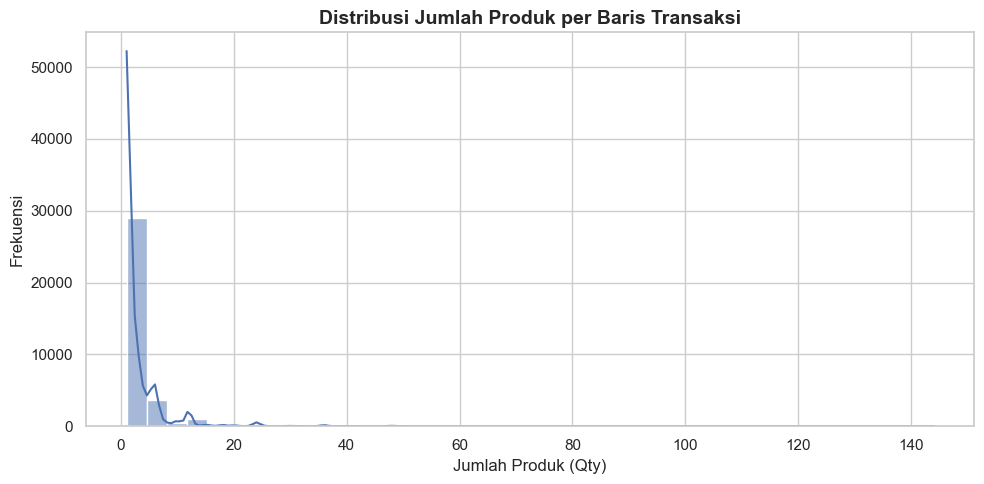

In [15]:

# ============================================================
# DISTRIBUSI JUMLAH PRODUK PER TRANSAKSI
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_transaksi,
    x="Qty",
    bins=40,
    kde=True
)

plt.title(
    "Distribusi Jumlah Produk per Baris Transaksi",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Jumlah Produk (Qty)")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()


In [16]:

# ============================================================
# IDENTIFIKASI TRANSAKSI PENJUALAN DAN RETUR
# ============================================================

df_transaksi["Sales Invoice"] = (
    df_transaksi["Sales Invoice"].astype(str)
)

df_transaksi["Jenis_Transaksi"] = np.where(
    df_transaksi["Sales Invoice"]
    .str.startswith("ACC-SINV-RET"),
    "Retur",
    "Penjualan"
)

ringkasan_transaksi = (
    df_transaksi
    .groupby("Jenis_Transaksi")
    .agg(
        Jumlah_Baris=("Qty", "size"),
        Jumlah_Invoice=("Sales Invoice", "nunique"),
        Total_Qty=("Qty", "sum"),
        Total_Nilai=("Total", "sum")
    )
)

display(ringkasan_transaksi)


,Jumlah_Baris,Jumlah_Invoice,Total_Qty,Total_Nilai
Jenis_Transaksi,,,,
Penjualan,34392,6133,95504,15363079423
Retur,170,121,209,-45485950


In [17]:

# ============================================================
# CONTOH NOMOR INVOICE
# ============================================================

print("Contoh invoice penjualan:")

display(
    df_transaksi.loc[
        df_transaksi["Jenis_Transaksi"] == "Penjualan",
        ["Sales Invoice", "Tanggal", "Qty", "Total"]
    ].head()
)

print("\nContoh invoice retur:")

display(
    df_transaksi.loc[
        df_transaksi["Jenis_Transaksi"] == "Retur",
        ["Sales Invoice", "Tanggal", "Qty", "Total"]
    ].head()
)


Contoh invoice penjualan:


,Sales Invoice,Tanggal,Qty,Total
0,ACC-SINV-2026-05722,2026-03-01,1,750000
1,ACC-SINV-2026-05722,2026-03-01,6,654000
2,ACC-SINV-2026-05722,2026-03-01,12,1392000
3,ACC-SINV-2026-05722,2026-03-01,3,477000
4,ACC-SINV-2026-05723,2026-03-01,1,116000



Contoh invoice retur:


,Sales Invoice,Tanggal,Qty,Total
1701,ACC-SINV-RET-2026-00034,2026-03-05,1,-190300
1702,ACC-SINV-RET-2026-00034,2026-03-05,1,-187000
1703,ACC-SINV-RET-2026-00035,2026-03-05,3,-45000
1704,ACC-SINV-RET-2026-00035,2026-03-05,1,-34650
2096,ACC-SINV-RET-2026-00036,2026-03-06,2,-123200


In [18]:

# ============================================================
# AGREGASI PENJUALAN HARIAN SELURUH PRODUK
# ============================================================

# Memisahkan transaksi penjualan
data_penjualan = df_transaksi[
    df_transaksi["Jenis_Transaksi"] == "Penjualan"
].copy()

# Memisahkan transaksi retur
data_retur = df_transaksi[
    df_transaksi["Jenis_Transaksi"] == "Retur"
].copy()

# Agregasi Gross Qty per hari
gross_qty = (
    data_penjualan
    .groupby("Tanggal")["Qty"]
    .sum()
    .rename("Gross_Qty")
)

# Agregasi Return Qty per hari
return_qty = (
    data_retur
    .groupby("Tanggal")["Qty"]
    .sum()
    .rename("Return_Qty")
)

# Menggabungkan hasil agregasi
penjualan_harian = pd.concat(
    [gross_qty, return_qty],
    axis=1
).fillna(0)

# Menghitung Net Qty
penjualan_harian["Net_Qty"] = (
    penjualan_harian["Gross_Qty"]
    - penjualan_harian["Return_Qty"]
)

# Mengurutkan berdasarkan tanggal
penjualan_harian = (
    penjualan_harian
    .sort_index()
    .reset_index()
)

# Mengubah nama kolom tanggal
penjualan_harian = penjualan_harian.rename(
    columns={"Tanggal": "Tanggal"}
)

print("Hasil agregasi penjualan harian:")
display(penjualan_harian.head(10))

print("\nLima data terakhir:")
display(penjualan_harian.tail())


Hasil agregasi penjualan harian:


,Tanggal,Gross_Qty,Return_Qty,Net_Qty
0,2026-03-01,62,0.00,62.00
1,2026-03-02,1009,0.00,"1,009.00"
2,2026-03-03,1025,0.00,"1,025.00"
3,2026-03-04,1052,0.00,"1,052.00"
4,2026-03-05,1063,6.00,"1,057.00"
5,2026-03-06,1351,9.00,"1,342.00"
6,2026-03-07,763,0.00,763.00
7,2026-03-08,261,0.00,261.00
8,2026-03-09,1592,0.00,"1,592.00"
9,2026-03-10,1151,0.00,"1,151.00"



Lima data terakhir:


,Tanggal,Gross_Qty,Return_Qty,Net_Qty
114,2026-06-26,559,0.00,559.00
115,2026-06-27,414,0.00,414.00
116,2026-06-28,30,0.00,30.00
117,2026-06-29,1646,8.00,"1,638.00"
118,2026-06-30,1754,8.00,"1,746.00"


In [19]:

# ============================================================
# STATISTIK DESKRIPTIF PENJUALAN HARIAN
# ============================================================

kolom_target = [
    "Gross_Qty",
    "Return_Qty",
    "Net_Qty"
]

statistik_harian = (
    penjualan_harian[kolom_target]
    .describe()
    .T
)

display(statistik_harian)

print("\nTotal Gross Qty:",
      penjualan_harian["Gross_Qty"].sum())

print("Total Return Qty:",
      penjualan_harian["Return_Qty"].sum())

print("Total Net Qty:",
      penjualan_harian["Net_Qty"].sum())


,count,mean,std,min,25%,50%,75%,max
Gross_Qty,119.00,802.55,660.68,7.00,346.50,763.00,"1,086.00","5,234.00"
Return_Qty,119.00,1.76,3.77,0.00,0.00,0.00,0.50,23.00
Net_Qty,119.00,800.80,659.73,7.00,346.50,763.00,"1,084.50","5,223.00"



Total Gross Qty: 95504
Total Return Qty: 209.0
Total Net Qty: 95295.0


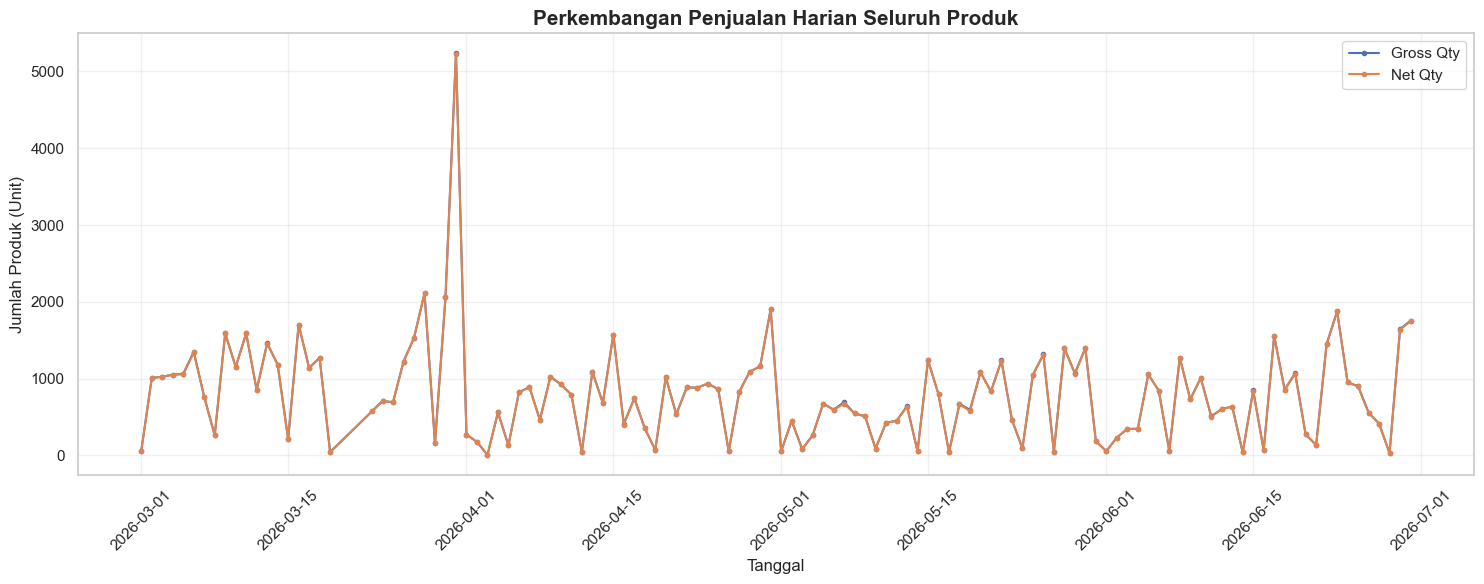

In [20]:

# ============================================================
# VISUALISASI PENJUALAN HARIAN
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    penjualan_harian["Tanggal"],
    penjualan_harian["Gross_Qty"],
    label="Gross Qty",
    linewidth=1.5,
    marker="o",
    markersize=3
)

plt.plot(
    penjualan_harian["Tanggal"],
    penjualan_harian["Net_Qty"],
    label="Net Qty",
    linewidth=1.5,
    marker="o",
    markersize=3
)

plt.title(
    "Perkembangan Penjualan Harian Seluruh Produk",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Produk (Unit)")

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


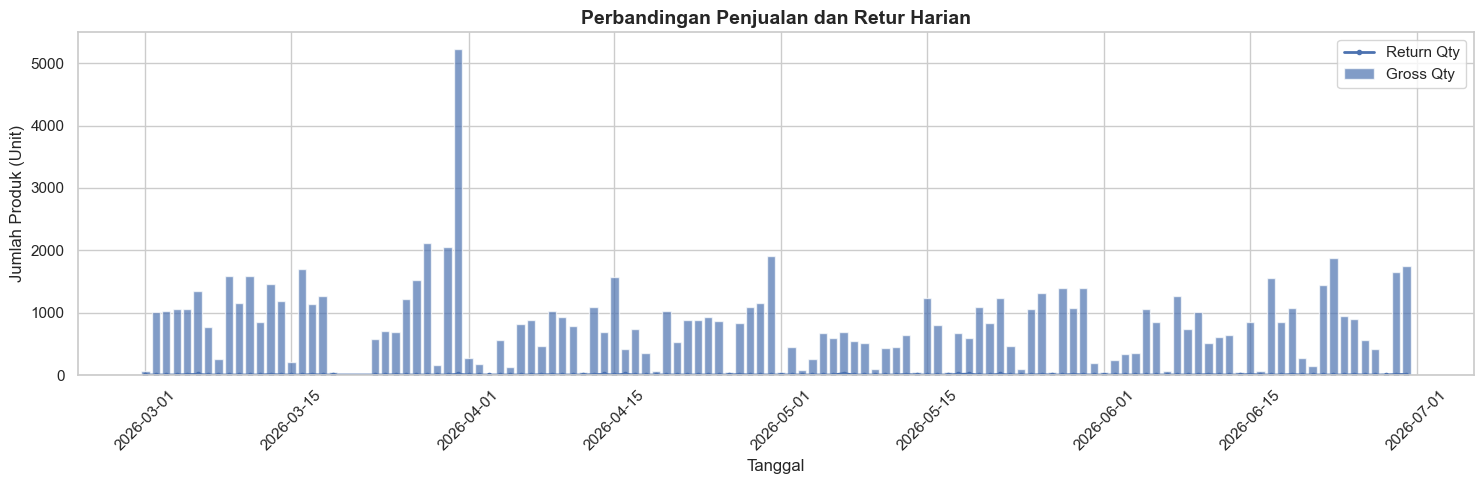

In [24]:

# ============================================================
# VISUALISASI GROSS QTY DAN RETURN QTY
# ============================================================

plt.figure(figsize=(15, 5))

plt.bar(
    penjualan_harian["Tanggal"],
    penjualan_harian["Gross_Qty"],
    label="Gross Qty",
    alpha=0.7
)

plt.plot(
    penjualan_harian["Tanggal"],
    penjualan_harian["Return_Qty"],
    label="Return Qty",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.title(
    "Perbandingan Penjualan dan Retur Harian",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Produk (Unit)")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [25]:

# ============================================================
# INVESTIGASI DUPLIKASI IDENTIK
# ============================================================

# Mengambil seluruh baris yang terindikasi duplikat
data_duplikat = df_transaksi[
    df_transaksi.duplicated(keep=False)
].copy()

print("Jumlah baris terindikasi duplikat:",
      len(data_duplikat))

print("\nContoh kelompok duplikasi:")
display(
    data_duplikat[
        [
            "Tanggal",
            "Sales Invoice",
            "Item Code",
            "Item Name",
            "Qty",
            "Harga",
            "Total"
        ]
    ].head(20)
)

# Menghitung jumlah kelompok baris yang benar-benar berulang
kelompok_duplikat = (
    data_duplikat
    .groupby(list(df_transaksi.columns), dropna=False)
    .size()
    .reset_index(name="Frekuensi")
)

kelompok_duplikat = kelompok_duplikat[
    kelompok_duplikat["Frekuensi"] > 1
]

print("\nJumlah kelompok data identik:",
      len(kelompok_duplikat))

display(kelompok_duplikat.head(10))


Jumlah baris terindikasi duplikat: 5685

Contoh kelompok duplikasi:


,Tanggal,Sales Invoice,Item Code,Item Name,Qty,Harga,Total
9,2026-03-01,ACC-SINV-2026-05724,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,1,103000,103000
10,2026-03-01,ACC-SINV-2026-05724,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,1,103000,103000
11,2026-03-01,ACC-SINV-2026-05724,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,2,103000,206000
12,2026-03-01,ACC-SINV-2026-05724,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,2,103000,206000
32,2026-03-02,ACC-SINV-2026-05731,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,1,109000,109000
33,2026-03-02,ACC-SINV-2026-05731,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,1,109000,109000
35,2026-03-02,ACC-SINV-2026-05731,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,1,109000,109000
36,2026-03-02,ACC-SINV-2026-05731,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,7,142000,994000
37,2026-03-02,ACC-SINV-2026-05731,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,1,142000,142000
38,2026-03-02,ACC-SINV-2026-05731,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,7,142000,994000



Jumlah kelompok data identik: 2332


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Jenis_Transaksi,Frekuensi
0,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1,103000,103000,0,0,103000,Penjualan,2
1,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2,103000,206000,0,0,206000,Penjualan,2
2,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000,Penjualan,3
3,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,1,142000,142000,0,0,142000,Penjualan,2
4,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7,142000,994000,0,0,994000,Penjualan,3
5,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1010401045,IL VASTO Volume 30 Creme Peroxide 100 ML,Peroxide,1,34650,34650,0,0,34650,Penjualan,2
6,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1010601011,IL VASTO Smartplex Keratin Infusion 250 ML,Smartplex,1,401500,401500,0,0,401500,Penjualan,3
7,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1010601021,IL VASTO Smartplex Filler Drops 250 ML,Smartplex,1,423500,423500,0,0,423500,Penjualan,3
8,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1020204011,Terra Diverde Pre Treatment Hair Scrub 30Ml,Scalp Detox,2,38500,77000,0,0,77000,Penjualan,2
9,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1050201021,Sleek Et Lisse Normal Curly Hair Step 1 & Step...,Straight System,1,88000,88000,0,0,88000,Penjualan,2


In [26]:
data_duplikat_kombinasi = df_transaksi[
    df_transaksi.duplicated(
        subset=["Tanggal", "Sales Invoice", "Item Code"],
        keep=False
    )
].copy()

display(
    data_duplikat_kombinasi[
        [
            "Tanggal",
            "Sales Invoice",
            "Customer",
            "Item Code",
            "Item Name",
            "Qty",
            "Total"
        ]
    ].sort_values(
        by=["Tanggal", "Sales Invoice", "Item Code"]
    ).head(30)
)

,Tanggal,Sales Invoice,Customer,Item Code,Item Name,Qty,Total
9,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,1,103000
10,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,1,103000
11,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,2,206000
12,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,2,206000
30,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,1010206021,IL VASTO Classico Hair Cream Colorant Red 6.66...,5,515000
31,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,1010206021,IL VASTO Classico Hair Cream Colorant Red 6.66...,7,721000
41,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,1010208071,ILVASTO Silver Hair Cream Colorant No. 12.10 A...,9,981000
42,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,1010208071,ILVASTO Silver Hair Cream Colorant No. 12.10 A...,3,327000
32,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,1,109000
33,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,1,109000


In [27]:
# Mengelompokkan baris identik dan menghitung frekuensinya
frekuensi_duplikat = (
    df_transaksi
    .groupby(list(df_transaksi.columns), dropna=False)
    .size()
    .reset_index(name="Frekuensi")
)

frekuensi_duplikat = frekuensi_duplikat[
    frekuensi_duplikat["Frekuensi"] > 1
]

display(frekuensi_duplikat.head(20))

,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Jenis_Transaksi,Frekuensi
8,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1,103000,103000,0,0,103000,Penjualan,2
9,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2,103000,206000,0,0,206000,Penjualan,2
32,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000,Penjualan,3
34,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,1,142000,142000,0,0,142000,Penjualan,2
35,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7,142000,994000,0,0,994000,Penjualan,3
63,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1010401045,IL VASTO Volume 30 Creme Peroxide 100 ML,Peroxide,1,34650,34650,0,0,34650,Penjualan,2
64,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1010601011,IL VASTO Smartplex Keratin Infusion 250 ML,Smartplex,1,401500,401500,0,0,401500,Penjualan,3
65,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1010601021,IL VASTO Smartplex Filler Drops 250 ML,Smartplex,1,423500,423500,0,0,423500,Penjualan,3
66,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1020204011,Terra Diverde Pre Treatment Hair Scrub 30Ml,Scalp Detox,2,38500,77000,0,0,77000,Penjualan,2
70,2026-03-02,ACC-SINV-2026-05750,Shopee,MKP,1050201021,Sleek Et Lisse Normal Curly Hair Step 1 & Step...,Straight System,1,88000,88000,0,0,88000,Penjualan,2


In [28]:

# ============================================================
# PEMERIKSAAN TANGGAL TANPA TRANSAKSI
# ============================================================

tanggal_pengecekan = pd.to_datetime([
    "2026-03-20",
    "2026-03-21",
    "2026-03-22"
])

for tanggal in tanggal_pengecekan:

    print("\nTanggal:", tanggal.date())

    data_tanggal = df_transaksi[
        df_transaksi["Tanggal"].dt.normalize() == tanggal
    ]

    print("Jumlah baris transaksi:", len(data_tanggal))

    display(data_tanggal.head())



Tanggal: 2026-03-20
Jumlah baris transaksi: 0


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Jenis_Transaksi



Tanggal: 2026-03-21
Jumlah baris transaksi: 0


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Jenis_Transaksi



Tanggal: 2026-03-22
Jumlah baris transaksi: 0


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Jenis_Transaksi


In [29]:
# Menyalin data penjualan harian
data_ts = penjualan_harian.copy()

# Memastikan kolom tanggal bertipe datetime
data_ts["Tanggal"] = pd.to_datetime(data_ts["Tanggal"])

# Menjadikan tanggal sebagai index
data_ts = data_ts.set_index("Tanggal")

# Membuat kalender harian dari 1 Maret sampai 30 Juni 2026
indeks_harian = pd.date_range(
    start="2026-03-01",
    end="2026-06-30",
    freq="D"
)

# Menyesuaikan data dengan kalender harian
data_ts = data_ts.reindex(indeks_harian)

# Mengisi tanggal tanpa transaksi dengan nilai 0
kolom_qty = ["Gross_Qty", "Return_Qty", "Net_Qty"]

data_ts[kolom_qty] = data_ts[kolom_qty].fillna(0)

# Memberi nama index
data_ts.index.name = "Tanggal"

# Memeriksa hasil
print("Jumlah observasi:", len(data_ts))
print("\nJumlah nilai kosong:")
print(data_ts.isnull().sum())

display(data_ts.head())
display(data_ts.loc["2026-03-19":"2026-03-23"])

Jumlah observasi: 122

Jumlah nilai kosong:
Gross_Qty     0
Return_Qty    0
Net_Qty       0
dtype: int64


,Gross_Qty,Return_Qty,Net_Qty
Tanggal,,,
2026-03-01,62.00,0.00,62.00
2026-03-02,"1,009.00",0.00,"1,009.00"
2026-03-03,"1,025.00",0.00,"1,025.00"
2026-03-04,"1,052.00",0.00,"1,052.00"
2026-03-05,"1,063.00",6.00,"1,057.00"


,Gross_Qty,Return_Qty,Net_Qty
Tanggal,,,
2026-03-19,44.00,0.00,44.00
2026-03-20,0.00,0.00,0.00
2026-03-21,0.00,0.00,0.00
2026-03-22,0.00,0.00,0.00
2026-03-23,576.00,0.00,576.00


In [30]:
print(data_ts.loc["2026-03-19":"2026-03-23"])
print(data_ts.shape)
print(data_ts.isnull().sum())

            Gross_Qty  Return_Qty  Net_Qty
Tanggal                                   
2026-03-19      44.00        0.00    44.00
2026-03-20       0.00        0.00     0.00
2026-03-21       0.00        0.00     0.00
2026-03-22       0.00        0.00     0.00
2026-03-23     576.00        0.00   576.00
(122, 3)
Gross_Qty     0
Return_Qty    0
Net_Qty       0
dtype: int64


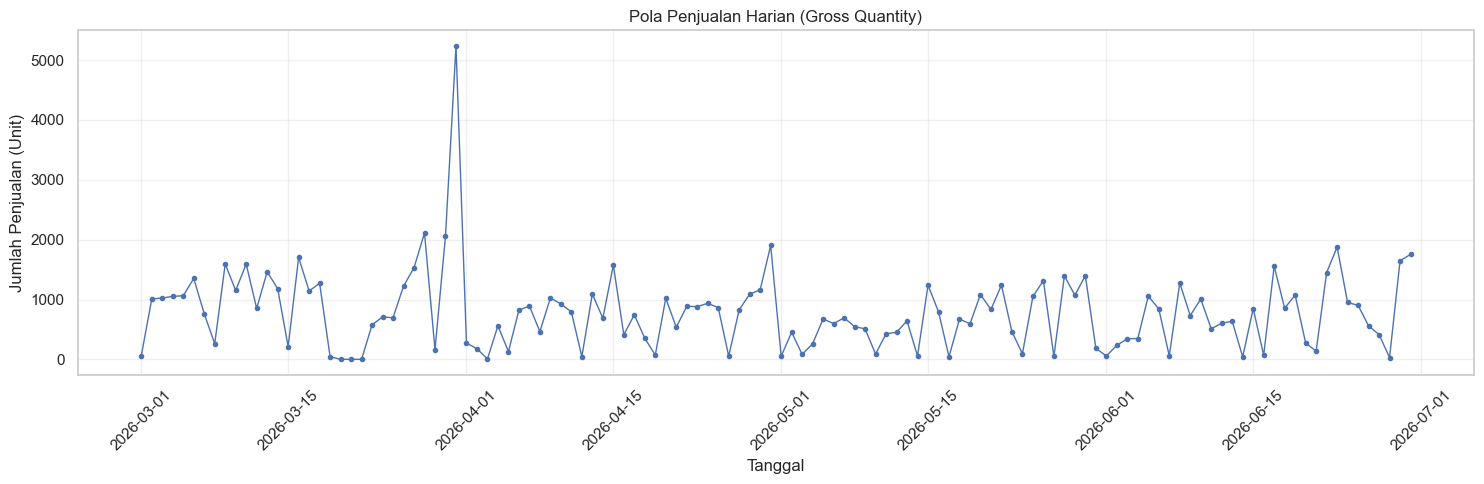

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    data_ts.index,
    data_ts["Gross_Qty"],
    marker="o",
    markersize=3,
    linewidth=1
)

plt.title("Pola Penjualan Harian (Gross Quantity)")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan (Unit)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
print("Statistik Deskriptif Gross_Qty:")
display(data_ts["Gross_Qty"].describe())

Statistik Deskriptif Gross_Qty:


count     122.00
mean      782.82
std       664.27
min         0.00
25%       273.25
50%       738.00
75%     1,080.25
max     5,234.00
Name: Gross_Qty, dtype: float64

In [33]:
# Mengurutkan penjualan dari yang terbesar
penjualan_tertinggi = (
    data_ts[["Gross_Qty"]]
    .sort_values(by="Gross_Qty", ascending=False)
)

print("10 Hari dengan Penjualan Tertinggi:")
display(penjualan_tertinggi.head(10))

10 Hari dengan Penjualan Tertinggi:


,Gross_Qty
Tanggal,
2026-03-31,"5,234.00"
2026-03-28,"2,112.00"
2026-03-30,"2,060.00"
2026-04-30,"1,904.00"
2026-06-23,"1,875.00"
2026-06-30,"1,754.00"
2026-03-16,"1,703.00"
2026-06-29,"1,646.00"
2026-03-09,"1,592.00"


In [34]:
# Mengelompokkan penjualan berdasarkan hari
rata_rata_harian = data_ts.copy()

rata_rata_harian["Hari"] = (
    rata_rata_harian.index.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

pola_mingguan = (
    rata_rata_harian
    .groupby("Hari")["Gross_Qty"]
    .mean()
    .reindex(urutan_hari)
)

display(pola_mingguan)

Hari
Monday      1,021.72
Tuesday     1,120.22
Wednesday     894.24
Thursday      775.12
Friday        847.00
Saturday      730.29
Sunday         97.56
Name: Gross_Qty, dtype: float64

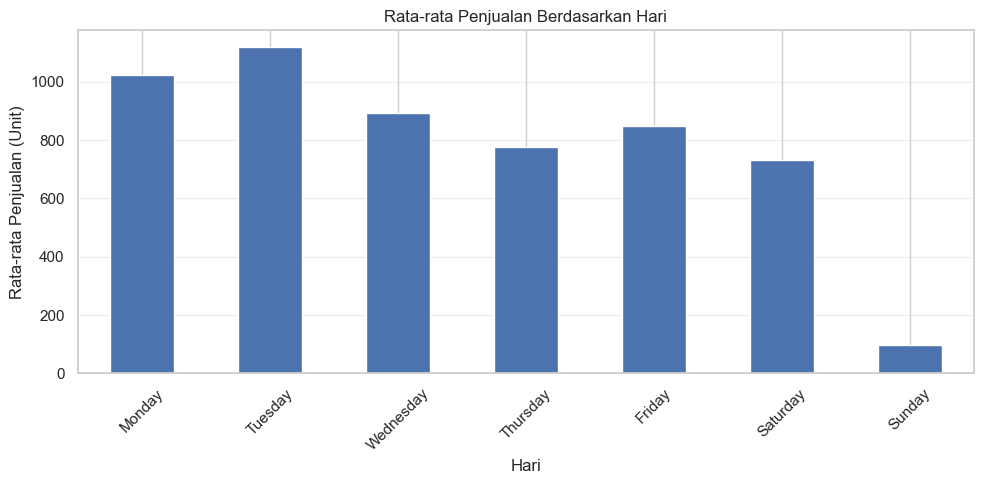

In [35]:
plt.figure(figsize=(10, 5))

pola_mingguan.plot(kind="bar")

plt.title("Rata-rata Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Penjualan (Unit)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
from statsmodels.tsa.stattools import adfuller

# Menentukan variabel target
y = data_ts["Gross_Qty"]

# Melakukan uji ADF
hasil_adf = adfuller(y)

print("HASIL UJI AUGMENTED DICKEY-FULLER")
print("--------------------------------")
print("ADF Statistic :", hasil_adf[0])
print("p-value       :", hasil_adf[1])
print("Jumlah Lag    :", hasil_adf[2])
print("Jumlah Observasi:", hasil_adf[3])

print("\nNilai Kritis:")
for tingkat, nilai in hasil_adf[4].items():
    print(f"{tingkat}: {nilai}")

# Interpretasi otomatis
if hasil_adf[1] < 0.05:
    print("\nKesimpulan: Data stasioner berdasarkan uji ADF.")
else:
    print("\nKesimpulan: Data belum stasioner berdasarkan uji ADF.")

HASIL UJI AUGMENTED DICKEY-FULLER
--------------------------------
ADF Statistic : -9.415814419451188
p-value       : 5.673470255621003e-16
Jumlah Lag    : 0
Jumlah Observasi: 121

Nilai Kritis:
1%: -3.485585145896754
5%: -2.885738566292665
10%: -2.5796759080663887

Kesimpulan: Data stasioner berdasarkan uji ADF.


In [37]:
from statsmodels.tsa.stattools import kpss

# Menggunakan data Gross_Qty
y = data_ts["Gross_Qty"]

# Melakukan uji KPSS
hasil_kpss = kpss(y, regression="c", nlags="auto")

print("HASIL UJI KPSS")
print("------------------------------")
print("KPSS Statistic :", hasil_kpss[0])
print("p-value        :", hasil_kpss[1])
print("Jumlah Lag     :", hasil_kpss[2])

print("\nNilai Kritis:")
for tingkat, nilai in hasil_kpss[3].items():
    print(f"{tingkat}: {nilai}")

if hasil_kpss[1] < 0.05:
    print("\nKesimpulan: Data belum stasioner berdasarkan uji KPSS.")
else:
    print("\nKesimpulan: Data stasioner berdasarkan uji KPSS.")

HASIL UJI KPSS
------------------------------
KPSS Statistic : 0.21577801131832108
p-value        : 0.1
Jumlah Lag     : 1

Nilai Kritis:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739

Kesimpulan: Data stasioner berdasarkan uji KPSS.


C:\Users\Maulida Shifa Annisa\AppData\Local\Temp\ipykernel_55604\3268219400.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  hasil_kpss = kpss(y, regression="c", nlags="auto")


In [38]:
print("HASIL UJI KPSS")
print("------------------------------")
print("KPSS Statistic :", hasil_kpss[0])
print("p-value        :", hasil_kpss[1])
print("Jumlah Lag     :", hasil_kpss[2])

print("\nNilai Kritis:")
for tingkat, nilai in hasil_kpss[3].items():
    print(f"{tingkat}: {nilai}")

HASIL UJI KPSS
------------------------------
KPSS Statistic : 0.21577801131832108
p-value        : 0.1
Jumlah Lag     : 1

Nilai Kritis:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739


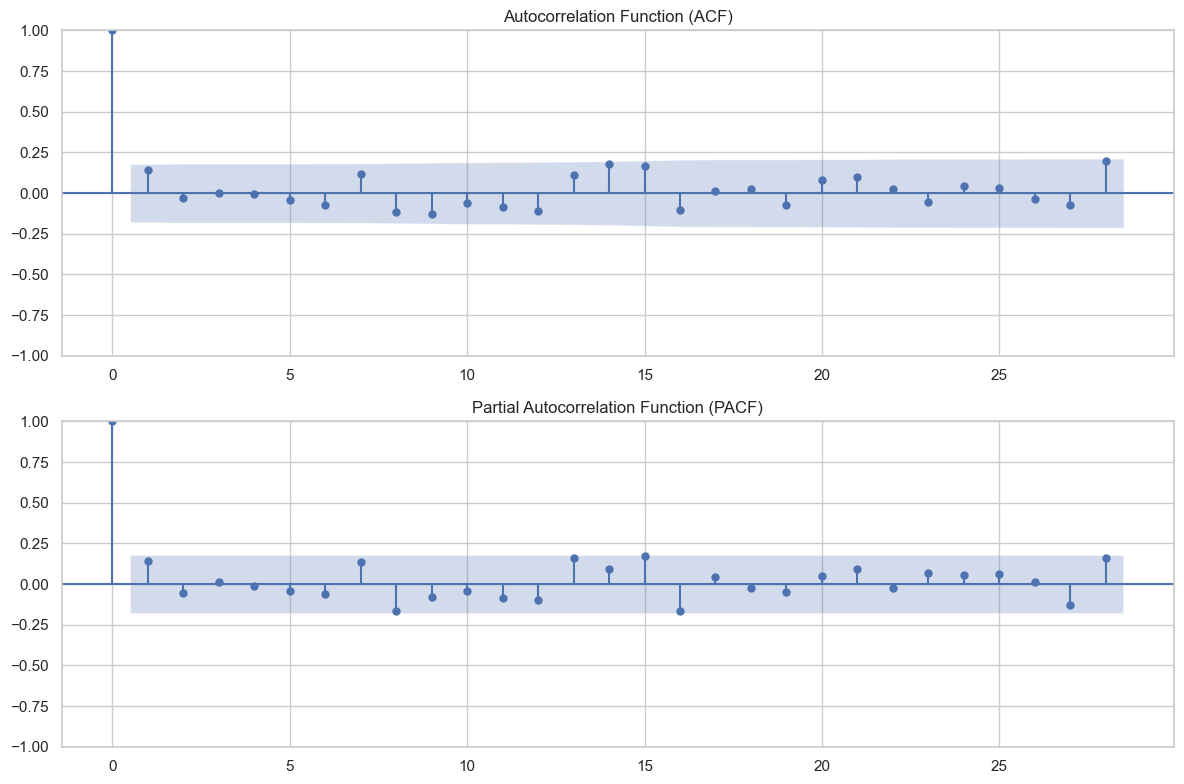

In [39]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Data target
y = data_ts["Gross_Qty"]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Grafik ACF
plot_acf(
    y,
    lags=28,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")

# Grafik PACF
plot_pacf(
    y,
    lags=28,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

In [40]:

# =====================================================
# PEMERIKSAAN AUTOKORELASI MUSIMAN
# =====================================================

from statsmodels.tsa.stattools import acf
import pandas as pd

y = data_ts["Gross_Qty"]

hasil_acf = acf(y, nlags=35, fft=False)

lag_musiman = [7, 14, 21, 28, 35]

tabel_musiman = pd.DataFrame({
    "Lag": lag_musiman,
    "ACF": [hasil_acf[lag] for lag in lag_musiman]
})

print("AUTOKORELASI PADA LAG MUSIMAN")
display(tabel_musiman)


AUTOKORELASI PADA LAG MUSIMAN


,Lag,ACF
0,7,0.12
1,14,0.18
2,21,0.10
3,28,0.20
4,35,0.10


In [41]:
print("KPSS Statistic:", hasil_kpss[0])
print("p-value:", hasil_kpss[1])
print("Jumlah Lag:", hasil_kpss[2])

KPSS Statistic: 0.21577801131832108
p-value: 0.1
Jumlah Lag: 1


PEMBAGIAN DATA TRAINING DAN TESTING
----------------------------------
Total observasi : 122
Data training   : 97
Data testing    : 25

Periode Training:
2026-03-01 00:00:00 sampai 2026-06-05 00:00:00

Periode Testing:
2026-06-06 00:00:00 sampai 2026-06-30 00:00:00


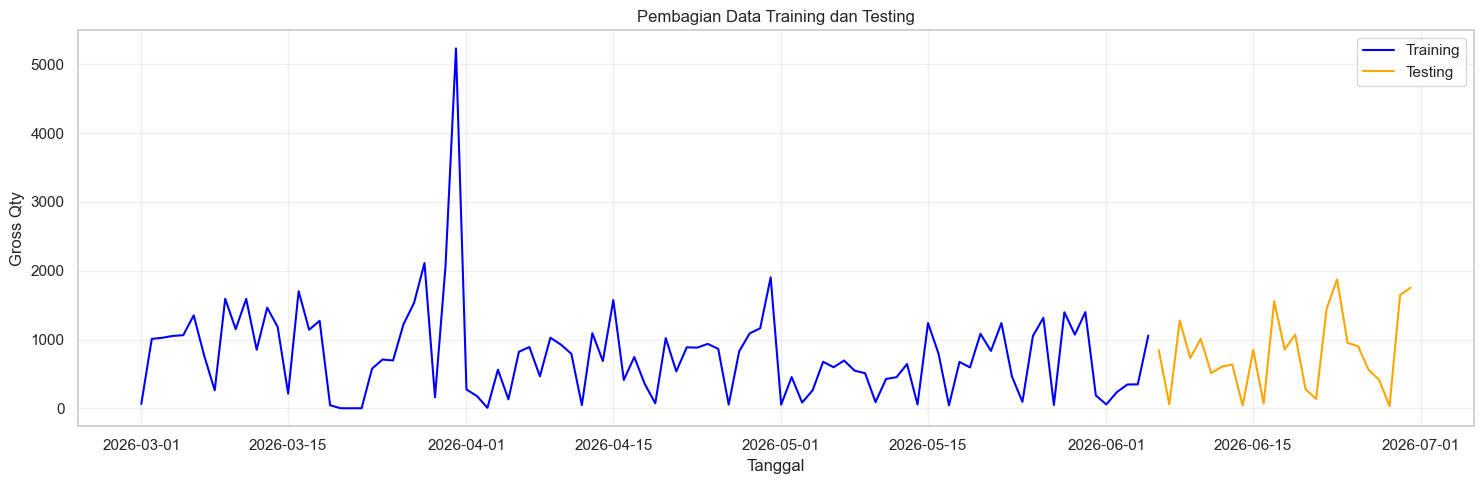

In [42]:

# =====================================================
# PEMBAGIAN DATA TRAINING DAN TESTING
# =====================================================

# Menentukan variabel target
y = data_ts["Gross_Qty"].astype(float)

# Menentukan ukuran data training
n_train = int(len(y) * 0.80)

# Membagi data secara kronologis
train = y.iloc[:n_train]
test = y.iloc[n_train:]

# Menampilkan informasi pembagian data
print("PEMBAGIAN DATA TRAINING DAN TESTING")
print("----------------------------------")

print("Total observasi :", len(y))
print("Data training   :", len(train))
print("Data testing    :", len(test))

print("\nPeriode Training:")
print(train.index.min(), "sampai", train.index.max())

print("\nPeriode Testing:")
print(test.index.min(), "sampai", test.index.max())

# Visualisasi
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(train.index, train,
         label="Training", color="blue")

plt.plot(test.index, test,
         label="Testing", color="orange")

plt.title("Pembagian Data Training dan Testing")
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [43]:

# ============================================================
# TAHAP PEMODELAN SARIMA
# ESTIMASI BEBERAPA KANDIDAT MODEL
# ============================================================

import pandas as pd
import numpy as np
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Menghilangkan warning yang tidak diperlukan saat proses fitting
warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. MENYIAPKAN DATA
# ------------------------------------------------------------

y = data_ts["Gross_Qty"].astype(float).asfreq("D")

# Membagi data training dan testing
n_train = int(len(y) * 0.80)

train = y.iloc[:n_train]
test = y.iloc[n_train:]

print("Jumlah data training:", len(train))
print("Jumlah data testing :", len(test))


# ------------------------------------------------------------
# 2. MENENTUKAN KANDIDAT SARIMA
# ------------------------------------------------------------

kandidat_model = [
    ((0, 0, 0), (0, 0, 0, 0)),
    ((1, 0, 0), (0, 0, 0, 0)),
    ((0, 0, 1), (0, 0, 0, 0)),
    ((1, 0, 1), (0, 0, 0, 0)),
    ((0, 0, 0), (1, 0, 0, 7)),
    ((0, 0, 0), (0, 0, 1, 7)),
    ((1, 0, 0), (1, 0, 0, 7)),
    ((0, 0, 1), (0, 0, 1, 7))
]


# ------------------------------------------------------------
# 3. ESTIMASI MODEL DAN FORECASTING
# ------------------------------------------------------------

hasil_model = []
forecast_model = {}

for i, (order, seasonal_order) in enumerate(kandidat_model, start=1):

    nama_model = f"SARIMA{order}x{seasonal_order}"

    try:
        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        hasil_fit = model.fit(disp=False, maxiter=500)

        # Forecast sepanjang periode testing
        prediksi = hasil_fit.forecast(steps=len(test))

        # Evaluasi forecasting
        mae = mean_absolute_error(test, prediksi)

        rmse = np.sqrt(
            mean_squared_error(test, prediksi)
        )

        wape = (
            np.sum(np.abs(test.values - prediksi.values))
            / np.sum(np.abs(test.values))
        ) * 100

        hasil_model.append({
            "Model": nama_model,
            "Order": order,
            "Seasonal Order": seasonal_order,
            "AIC": hasil_fit.aic,
            "BIC": hasil_fit.bic,
            "MAE": mae,
            "RMSE": rmse,
            "WAPE (%)": wape,
            "Konvergen": hasil_fit.mle_retvals.get(
                "converged", False
            )
        })

        forecast_model[nama_model] = prediksi

        print(f"Model {i}: {nama_model} berhasil diestimasi")

    except Exception as e:
        print(f"Model {i}: {nama_model} gagal")
        print("Penyebab:", str(e))


# ------------------------------------------------------------
# 4. MEMBUAT TABEL HASIL
# ------------------------------------------------------------

tabel_sarima = pd.DataFrame(hasil_model)

tabel_sarima = tabel_sarima.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("\nHASIL PERBANDINGAN KANDIDAT SARIMA")
display(tabel_sarima.round(4))


Jumlah data training: 97
Jumlah data testing : 25
Model 1: SARIMA(0, 0, 0)x(0, 0, 0, 0) berhasil diestimasi
Model 2: SARIMA(1, 0, 0)x(0, 0, 0, 0) berhasil diestimasi
Model 3: SARIMA(0, 0, 1)x(0, 0, 0, 0) berhasil diestimasi
Model 4: SARIMA(1, 0, 1)x(0, 0, 0, 0) berhasil diestimasi
Model 5: SARIMA(0, 0, 0)x(1, 0, 0, 7) berhasil diestimasi
Model 6: SARIMA(0, 0, 0)x(0, 0, 1, 7) berhasil diestimasi
Model 7: SARIMA(1, 0, 0)x(1, 0, 0, 7) berhasil diestimasi
Model 8: SARIMA(0, 0, 1)x(0, 0, 1, 7) berhasil diestimasi

HASIL PERBANDINGAN KANDIDAT SARIMA


,Model,Order,Seasonal Order,AIC,BIC,MAE,RMSE,WAPE (%),Konvergen
0,"SARIMA(1, 0, 1)x(0, 0, 0, 0)","(1, 0, 1)","(0, 0, 0, 0)","1,520.25","1,527.92",496.73,625.70,61.78,True
1,"SARIMA(0, 0, 0)x(1, 0, 0, 7)","(0, 0, 0)","(1, 0, 0, 7)","1,472.36","1,477.36",642.88,878.56,79.96,True
2,"SARIMA(1, 0, 0)x(1, 0, 0, 7)","(1, 0, 0)","(1, 0, 0, 7)","1,443.91","1,451.37",696.67,906.44,86.65,True
3,"SARIMA(1, 0, 0)x(0, 0, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)","1,562.38","1,567.50",760.33,935.25,94.57,True
4,"SARIMA(0, 0, 1)x(0, 0, 1, 7)","(0, 0, 1)","(0, 0, 1, 7)","1,439.53","1,446.97",752.03,949.76,93.54,True
5,"SARIMA(0, 0, 0)x(0, 0, 1, 7)","(0, 0, 0)","(0, 0, 1, 7)","1,476.74","1,481.72",772.81,956.45,96.12,True
6,"SARIMA(0, 0, 1)x(0, 0, 0, 0)","(0, 0, 1)","(0, 0, 0, 0)","1,564.53","1,569.64",785.76,960.99,97.73,True
7,"SARIMA(0, 0, 0)x(0, 0, 0, 0)","(0, 0, 0)","(0, 0, 0, 0)","1,608.88","1,611.44",804.00,972.59,100.00,True


In [44]:

# ============================================================
# DIAGNOSTIK RESIDUAL SARIMA(1,0,1)
# ============================================================

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Mengestimasi ulang model kandidat terbaik
model_terbaik = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_terbaik = model_terbaik.fit(
    disp=False,
    maxiter=500
)

print(hasil_terbaik.summary())


                               SARIMAX Results                                
Dep. Variable:              Gross_Qty   No. Observations:                   97
Model:               SARIMAX(1, 0, 1)   Log Likelihood                -757.127
Date:                Tue, 10 Nov 2026   AIC                           1520.254
Time:                        04:58:54   BIC                           1527.916
Sample:                    03-01-2026   HQIC                          1523.350
                         - 06-05-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9934      0.006    174.459      0.000       0.982       1.005
ma.L1         -0.9917      0.094    -10.559      0.000      -1.176      -0.808
sigma2       5.83e+05   1.95e-07   2.98e+12      0.0

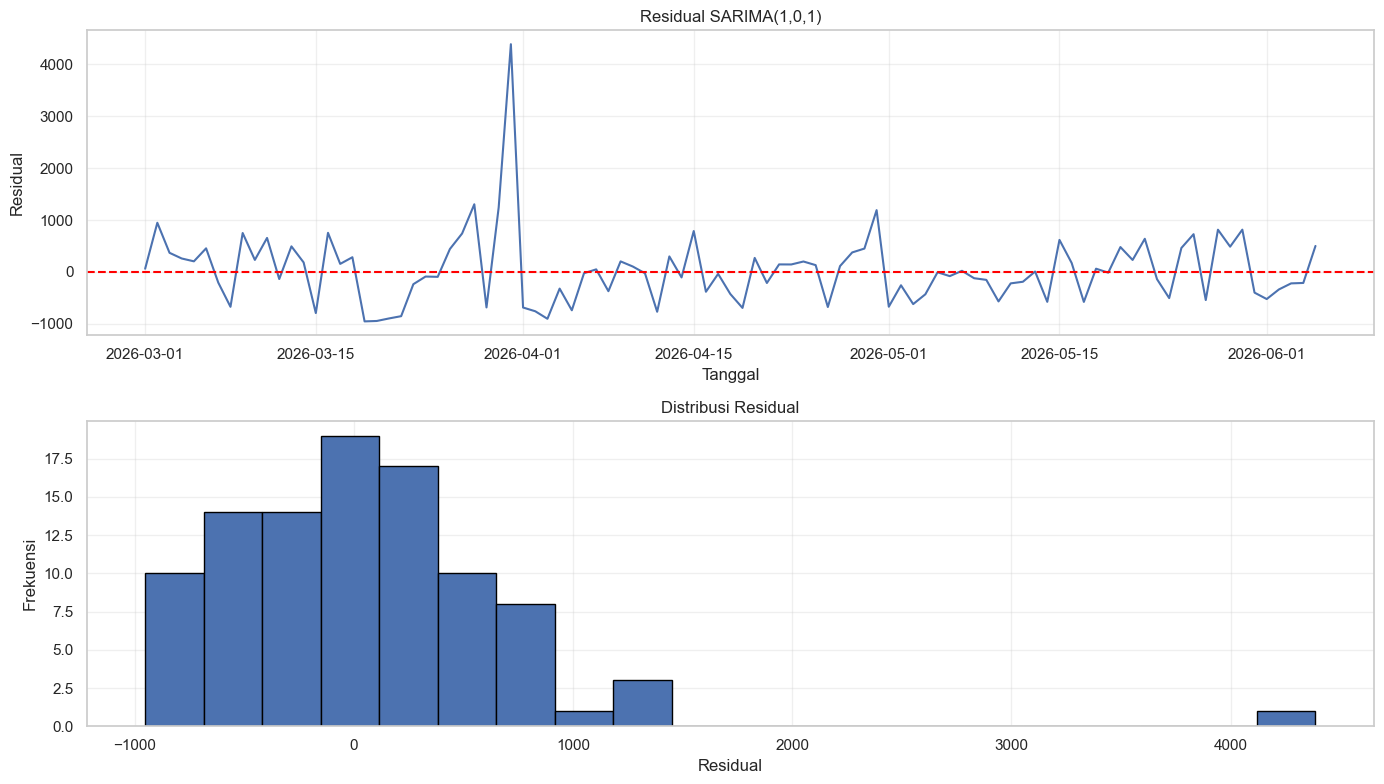

In [45]:

import matplotlib.pyplot as plt
import pandas as pd

# Mengambil residual model
residual = hasil_terbaik.resid.dropna()

# Membuat visualisasi
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Grafik residual
axes[0].plot(residual.index, residual)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residual SARIMA(1,0,1)")
axes[0].set_xlabel("Tanggal")
axes[0].set_ylabel("Residual")
axes[0].grid(alpha=0.3)

# Distribusi residual
axes[1].hist(residual, bins=20, edgecolor="black")
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frekuensi")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


<Figure size 1200x400 with 0 Axes>

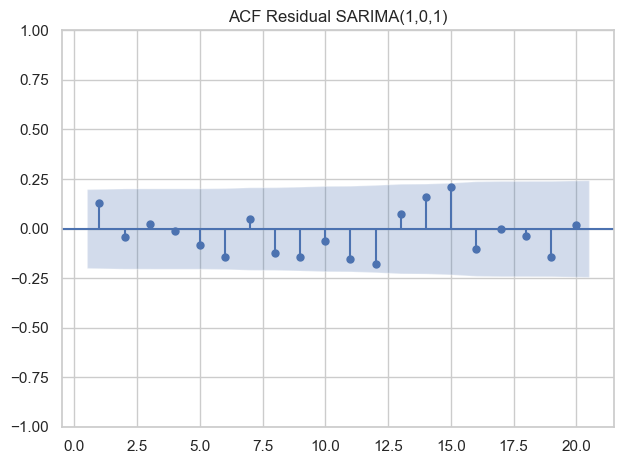

In [46]:

from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 4))

plot_acf(
    residual,
    lags=20,
    zero=False
)

plt.title("ACF Residual SARIMA(1,0,1)")
plt.tight_layout()
plt.show()


In [47]:

from statsmodels.stats.diagnostic import acorr_ljungbox

# Uji Ljung-Box pada beberapa lag
hasil_ljungbox = acorr_ljungbox(
    residual,
    lags=[7, 14, 21],
    model_df=2,
    return_df=True
)

print("HASIL UJI LJUNG-BOX")
print("===================")
display(hasil_ljungbox)

# Interpretasi
for lag, row in hasil_ljungbox.iterrows():
    print(f"\nLag {lag}")
    print("p-value:", row["lb_pvalue"])

    if row["lb_pvalue"] > 0.05:
        print("Residual tidak menunjukkan autokorelasi signifikan.")
    else:
        print("Residual masih menunjukkan autokorelasi signifikan.")


HASIL UJI LJUNG-BOX


,lb_stat,lb_pvalue
7,5.18,0.39
14,19.24,0.08
21,29.14,0.06



Lag 7
p-value: 0.39486791373057173
Residual tidak menunjukkan autokorelasi signifikan.

Lag 14
p-value: 0.08292154507643515
Residual tidak menunjukkan autokorelasi signifikan.

Lag 21
p-value: 0.06376877062567969
Residual tidak menunjukkan autokorelasi signifikan.


HASIL UJI JARQUE-BERA
---------------------
JB Statistic : 953.1750007728155
p-value      : 1.0487656102989569e-207
Residual menunjukkan penyimpangan dari distribusi normal.


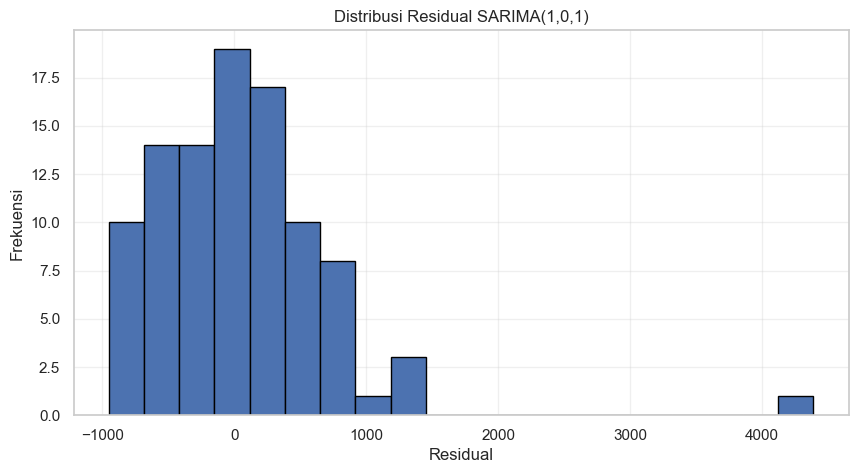

In [48]:

from scipy.stats import jarque_bera
import matplotlib.pyplot as plt

# Mengambil residual
residual = hasil_terbaik.resid.dropna()

# Uji Jarque-Bera
jb_stat, jb_pvalue = jarque_bera(residual)

print("HASIL UJI JARQUE-BERA")
print("---------------------")
print("JB Statistic :", jb_stat)
print("p-value      :", jb_pvalue)

if jb_pvalue > 0.05:
    print("Residual tidak menunjukkan penyimpangan normalitas yang signifikan.")
else:
    print("Residual menunjukkan penyimpangan dari distribusi normal.")

# Histogram residual
plt.figure(figsize=(10, 5))
plt.hist(residual, bins=20, edgecolor="black")
plt.title("Distribusi Residual SARIMA(1,0,1)")
plt.xlabel("Residual")
plt.ylabel("Frekuensi")
plt.grid(alpha=0.3)
plt.show()


In [49]:

from scipy.stats import skew, kurtosis

print("ANALISIS KARAKTERISTIK RESIDUAL")
print("--------------------------------")
print("Skewness :", skew(residual))
print("Kurtosis :", kurtosis(residual, fisher=False))
print("Minimum  :", residual.min())
print("Maksimum :", residual.max())


ANALISIS KARAKTERISTIK RESIDUAL
--------------------------------
Skewness : 2.6126588940159894
Kurtosis : 17.440677532835863
Minimum  : -952.3779223396702
Maksimum : 4387.748084458058


<Figure size 800x600 with 0 Axes>

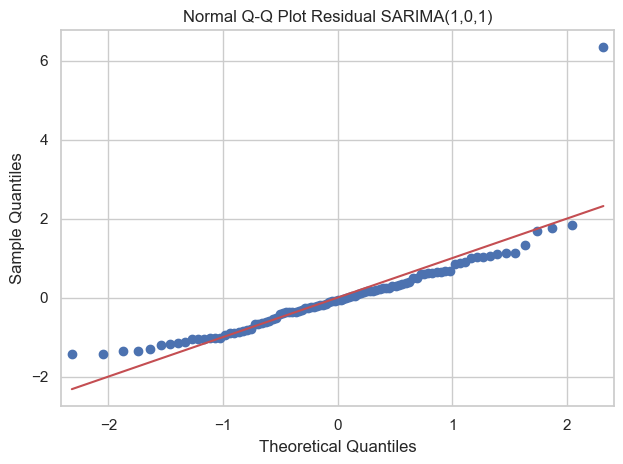

In [50]:

import matplotlib.pyplot as plt
import statsmodels.api as sm

plt.figure(figsize=(8, 6))

sm.qqplot(
    residual,
    line="s",
    fit=True
)

plt.title("Normal Q-Q Plot Residual SARIMA(1,0,1)")
plt.tight_layout()
plt.show()
